# 05 | Final Comparative Analysis and Research Conclusions
**Evaluating Underwater Image Enhancement for CNN-Based Robotic Segmentation**

This notebook presents the final synthesis of the experimental evidence documented in `01_data_exploration_cleaning.ipynb`, `02_unet_baseline.ipynb`, `03_underwater_image_enhancement.ipynb`, and `04_controlled_segmentation_evaluation.ipynb`. I examine whether CLAHE or FUnIE-GAN improves semantic segmentation when applied to the inputs of a frozen U-Net trained on unmodified underwater images. The analysis uses previously archived results; no model retraining, new inference, or test-driven parameter selection is performed. Conclusions are specific to the evaluated SUIM dataset, preprocessing configurations, and fixed-model protocol.

## 1. Research Overview and Objectives

Underwater image enhancement is often motivated by color attenuation, reduced contrast, and nonuniform illumination. However, a visually clearer image is not necessarily easier for a convolutional neural network to segment. I investigate this distinction by comparing unmodified RAW images with CLAHE- and FUnIE-GAN-enhanced inputs.

The experimental foundation was established through `01_data_exploration_cleaning.ipynb` (dataset curation and fixed splits), `02_unet_baseline.ipynb` (RAW-image U-Net training and checkpoint selection), `03_underwater_image_enhancement.ipynb` (locked enhancement procedures and validation-set image-quality analysis), and `04_controlled_segmentation_evaluation.ipynb` (paired evaluation on the official test set).

My primary outcome is dataset-level mean Intersection over Union (mIoU), supplemented by pixel accuracy, per-class IoU, plant and robot error patterns, bootstrap uncertainty, and computational observations. The study tests **input enhancement for an existing RAW-trained model**; it does not compare separately trained enhancement-specific models.

## 2. Experimental Environment and Reproducibility

I consolidated the archived CSV, JSON, and NumPy records in the `Underwater_Research` directory without rerunning segmentation inference. The source experiment uses a locked 256 × 256, eight-class SUIM representation and a single selected U-Net checkpoint. I preserve the original data, labels, predictions, and experimental outputs.

The following analysis initializes the required libraries and identifies the saved enhancement and evaluation records. Missing files or inconsistent metadata are treated as integrity failures rather than replaced with estimated values. The final synthesis tables and figures are written to dedicated output directories.

In [ ]:
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

ROOT = Path('/content/drive/MyDrive/Underwater_Research')
NB03 = ROOT / 'results/tables/notebook_03'
NB04 = ROOT / 'results/tables/notebook_04'
OUT = ROOT / 'results/tables/notebook_05'
FIG = ROOT / 'results/figures/notebook_05'
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
METHODS = ['raw', 'clahe', 'funie_gan']
LABELS = {'raw':'RAW', 'clahe':'CLAHE', 'funie_gan':'FUnIE-GAN'}
CLASSES = ['water','diver','plant','wreck','robot','reef','fish','sea-floor']
SEED = 42
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':180})
print('Research directory:', ROOT)
print('Synthesis only: saved records; no inference or training.')

Mounted at /content/drive
Research directory: /content/drive/MyDrive/Underwater_Research
Synthesis only: saved records; no inference or training.


## 3. Experimental Evidence Verification

Before interpreting performance, I verified the continuity of the experimental records. `01_data_exploration_cleaning.ipynb` established a fixed split of 1,204 training, 214 validation, and 110 test images. `02_unet_baseline.ipynb` selected the best RAW-trained U-Net checkpoint at epoch 112. `03_underwater_image_enhancement.ipynb` archived 648 enhanced validation and test images, while `04_controlled_segmentation_evaluation.ipynb` evaluated 110 matched test identities under three conditions, producing 330 prediction masks.

The saved confusion-count array has dimensions **110 × 3 × 8 × 8**. The ground-truth class counts are identical across conditions, and the enhancement manifest and configuration checks pass. This supports a controlled comparison in which the model, test identities, and annotations are fixed while the image representation changes. These checks establish consistency of the archived records, not independent replication on another dataset.

In [ ]:
def require(path):
    assert path.is_file(), f'Missing research record: {path}'
    return path

def load_csv(name, directory=NB04):
    return pd.read_csv(require(directory / name))

overall = load_csv('overall_metrics.csv')
per_class = load_csv('per_class_metrics.csv')
bootstrap = load_csv('paired_bootstrap_95ci.csv')
per_image = load_csv('paired_per_image_iou.csv')
inference = load_csv('segmentation_inference_timing.csv')
pipeline = load_csv('indicative_pipeline_timing.csv')
config = json.loads(require(NB04/'evaluation_config.json').read_text())
conf = np.load(require(NB04/'paired_confusion_counts.npz'), allow_pickle=False)
cms = conf['cms']
stems = conf['stems'].astype(str).tolist()
methods = conf['methods'].astype(str).tolist()
assert cms.shape == (110,3,8,8) and methods == METHODS and len(set(stems)) == 110
assert set(overall.method) == set(METHODS)
assert set(per_class['class']) == set(CLASSES)
assert set(per_class.method) == set(METHODS)
assert config['checkpoint_best_epoch'] == 112 and config['test_images'] == 110
assert config['manifest_sha256'] == '30713993fb9fbd669bee764758ccd3c2fd83cf9af953295c0940e5ccdca97b69'
assert config['bootstrap_replicates'] == 2000
assert cms.sum() == 110*3*256*256
assert np.array_equal(cms[:,0].sum(axis=(0,2)),cms[:,1].sum(axis=(0,2)))
assert np.array_equal(cms[:,0].sum(axis=(0,2)),cms[:,2].sum(axis=(0,2)))
assert len(per_image) == 110 and set(per_image['stem'].astype(str)) == set(stems)
assert (NB03/'enhancement_config.json').is_file() and (NB03/'enhancement_manifest.csv').is_file()
enh_config = json.loads((NB03/'enhancement_config.json').read_text())
enh_manifest = load_csv('enhancement_manifest.csv', NB03)
assert enh_config['manifest_sha256'] == config['manifest_sha256']
assert len(enh_manifest) == 648
assert enh_manifest.groupby(['split','method']).size().to_dict() == {('val','clahe'):214,('val','funie_gan'):214,('test','clahe'):110,('test','funie_gan'):110}
assert hashlib.sha256((NB03/'enhancement_config.json').read_bytes()).hexdigest() == config['enhancement_config_sha256']
assert hashlib.sha256((NB03/'enhancement_manifest.csv').read_bytes()).hexdigest() == config['enhancement_manifest_sha256']
print('Verified: 110 test identities, 330 paired predictions, 648 enhancement records, frozen epoch-112 checkpoint metadata.')
print('Checkpoint SHA256:',config['checkpoint_sha256'])
display(overall.round(4))

Verified: 110 test identities, 330 paired predictions, 648 enhancement records, frozen epoch-112 checkpoint metadata.
Checkpoint SHA256: 2244ff0337185bfba8d2621e7541bd373bfc7af0f0331af32155b464e51d466f


,method,miou,pixel_accuracy,delta_miou_vs_raw,delta_accuracy_vs_raw
0,raw,0.4423,0.7683,0.0000,0.0000
1,clahe,0.3180,0.5783,-0.1242,-0.1901
2,funie_gan,0.3301,0.6612,-0.1122,-0.1071


## 4. Consolidated Experimental Results

The unmodified RAW inputs produced the strongest overall segmentation results: **44.23% mIoU** and **76.83% pixel accuracy**. CLAHE achieved **31.80% mIoU** and **57.83% pixel accuracy**, corresponding to reductions of **12.42** and **19.01 percentage points** relative to RAW. FUnIE-GAN achieved **33.01% mIoU** and **66.12% pixel accuracy**, reductions of **11.22** and **10.71 percentage points**, respectively.

Both enhancement conditions therefore performed worse than RAW on the official 110-image test set. FUnIE-GAN retained more overall accuracy than CLAHE, but neither exceeded the baseline. These are dataset-level results calculated from pooled confusion counts, rather than averages of per-image IoU. They support a negative answer to the central question **for this frozen RAW-trained U-Net**, not a universal conclusion about enhancement or models trained on enhanced data.

,miou,pixel_accuracy,delta_miou_vs_raw,delta_accuracy_vs_raw
RAW,44.23%,76.83%,0.00%,0.00%
CLAHE,31.80%,57.83%,-12.42%,-19.01%
FUnIE-GAN,33.01%,66.12%,-11.22%,-10.71%


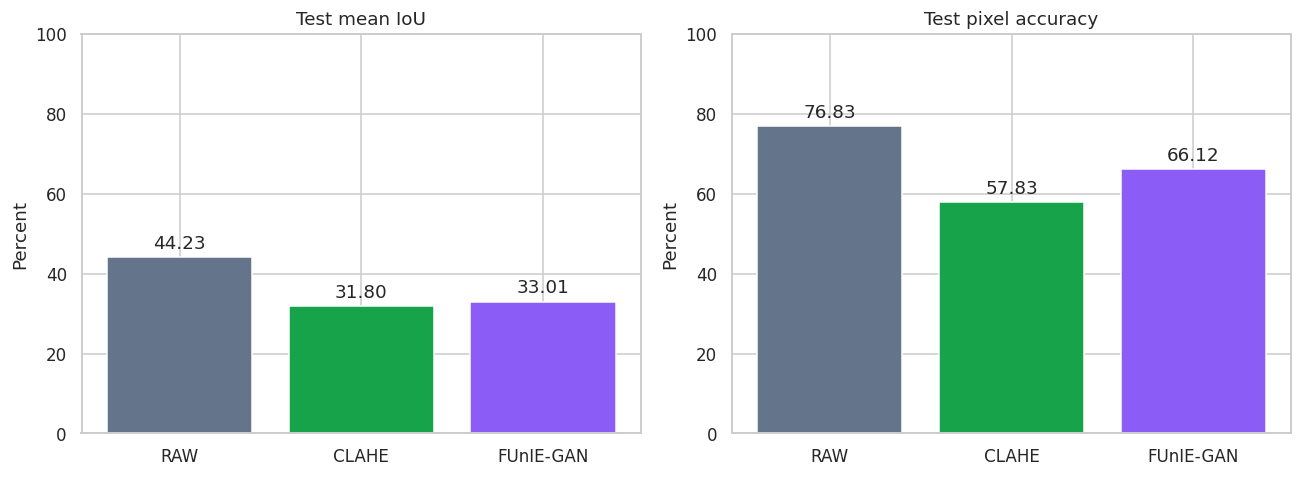

In [ ]:
view = overall.set_index('method').loc[METHODS].copy()

def pooled_metrics(cm):
    cm = np.asarray(cm, dtype=float)
    tp = np.diag(cm); gt = cm.sum(axis=1); pred = cm.sum(axis=0)
    union = gt + pred - tp
    iou = np.divide(tp, union, out=np.full(8,np.nan), where=union>0)
    return np.nanmean(iou), tp.sum()/cm.sum(), iou
for j,m in enumerate(METHODS):
    miou,accuracy,_ = pooled_metrics(cms[:,j].sum(axis=0))
    assert np.isclose(miou,view.loc[m,'miou'],atol=1e-9)
    assert np.isclose(accuracy,view.loc[m,'pixel_accuracy'],atol=1e-9)

summary = view[['miou','pixel_accuracy','delta_miou_vs_raw','delta_accuracy_vs_raw']].copy()
summary.index = [LABELS[m] for m in METHODS]
display(summary.style.format('{:.2%}'))
fig,axes = plt.subplots(1,2,figsize=(12,4.5))
for ax,field,title in zip(axes,['miou','pixel_accuracy'],['Test mean IoU','Test pixel accuracy']):
    vals=view[field].to_numpy()*100
    bars=ax.bar([LABELS[m] for m in METHODS],vals,color=['#64748b','#16a34a','#8b5cf6'])
    ax.bar_label(bars,fmt='%.2f',padding=3)
    ax.set(ylabel='Percent',title=title,ylim=(0,100))
fig.tight_layout();fig.savefig(FIG/'01_overall_comparison.png',bbox_inches='tight');plt.show()
summary.to_csv(OUT/'consolidated_overall_metrics.csv',index_label='condition')

## 5. Image Quality Versus Segmentation Performance

`03_underwater_image_enhancement.ipynb` showed that the two transformations changed measurable image properties on the **214-image validation set**. Relative to RAW, CLAHE increased mean luminance by **10.89**, luminance variation by **8.46**, and mean gradient magnitude by **49.78** in the recorded image-statistic units. FUnIE-GAN decreased mean luminance by **2.21**, increased luminance variation by **0.91**, and increased gradient magnitude by **7.51**. The recorded clipped-pixel fraction changed by **+0.0013** for CLAHE and **−0.0338** for FUnIE-GAN.

These results establish that the enhancement methods altered visual statistics, but the corresponding fixed-model segmentation results in `04_controlled_segmentation_evaluation.ipynb` were poorer than RAW. Greater contrast or gradient strength is therefore not sufficient evidence of improved recognition. A shift away from the appearance distribution learned during RAW training is one plausible explanation; the current experiment does not isolate that mechanism causally.

**Interpretive boundary:** the image-quality statistics summarize validation images, whereas the segmentation scores summarize test images. I compare their aggregate patterns descriptively and do not claim an image-by-image correlation across different splits.

In [ ]:
quality_context = pd.DataFrame([
    {'method':'CLAHE','validation_luminance_change':10.8943,'validation_luminance_variation_change':8.4576,'validation_gradient_change':49.7793,'validation_clipping_change':0.0013},
    {'method':'FUnIE-GAN','validation_luminance_change':-2.2061,'validation_luminance_variation_change':0.9121,'validation_gradient_change':7.5135,'validation_clipping_change':-0.0338},
])
# Notebook 03 values are the previously reported validation paired mean differences.
# They are not test-image measurements and are never merged by image identity.
quality_context.to_csv(OUT/'notebook_03_validation_quality_context.csv',index=False)
display(quality_context.round(4))
print('These validation-set descriptors are contextual, not paired with Notebook 04 test images.')

,method,validation_luminance_change,validation_luminance_variation_change,validation_gradient_change,validation_clipping_change
0,CLAHE,10.8943,8.4576,49.7793,0.0013
1,FUnIE-GAN,-2.2061,0.9121,7.5135,-0.0338


These validation-set descriptors are contextual, not paired with Notebook 04 test images.


## 6. Per-Class Segmentation Analysis

The aggregate decline was reflected across the eight semantic classes. RAW achieved the highest IoU for water (**83.39%**), diver (**57.75%**), wreck (**41.82%**), robot (**11.53%**), reef (**56.61%**), fish (**46.15%**), and sea-floor (**56.56%**). Plant IoU was **0.00%** in every condition. Neither CLAHE nor FUnIE-GAN improved the IoU of any class over RAW.

CLAHE caused particularly large reductions for water (**−38.78 percentage points**) and sea-floor (**−23.71 points**). FUnIE-GAN produced smaller water degradation (**−10.63 points**) but substantial reductions for wreck (**−17.07 points**) and sea-floor (**−16.29 points**). Class-specific differences demonstrate that enhancement does not affect all categories equally, even though the overall direction was unfavorable. These comparisons concern the existing frozen model, not the inherent visibility or learnability of each category.

method,RAW,CLAHE,FUnIE-GAN
class,,,
water,83.39%,44.61%,72.76%
diver,57.75%,50.84%,43.39%
plant,0.00%,0.00%,0.00%
wreck,41.82%,30.96%,24.76%
robot,11.53%,0.38%,3.69%
reef,56.61%,51.38%,44.51%
fish,46.15%,43.39%,34.71%
sea-floor,56.56%,32.85%,40.26%


,CLAHE − RAW,FUnIE-GAN − RAW
water,-38.78%,-10.63%
diver,-6.91%,-14.36%
plant,+0.00%,+0.00%
wreck,-10.87%,-17.07%
robot,-11.15%,-7.84%
reef,-5.23%,-12.10%
fish,-2.76%,-11.44%
sea-floor,-23.71%,-16.29%


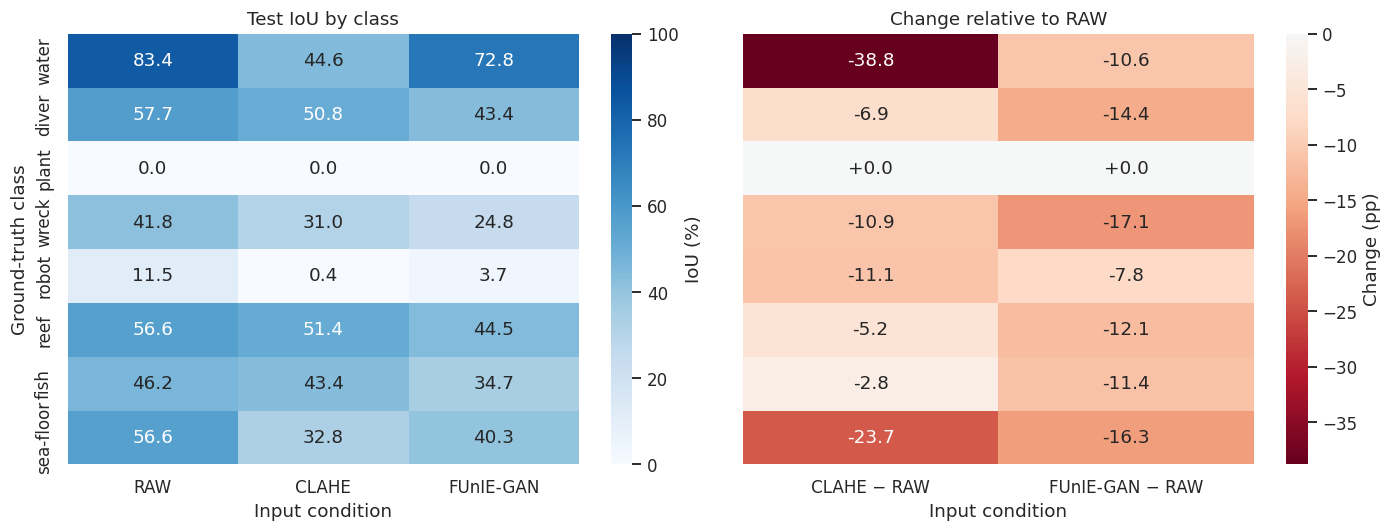

In [ ]:
class_pivot=per_class.pivot(index='class',columns='method',values='iou').reindex(CLASSES)[METHODS]
class_delta=pd.DataFrame({'CLAHE − RAW':class_pivot['clahe']-class_pivot['raw'],
                          'FUnIE-GAN − RAW':class_pivot['funie_gan']-class_pivot['raw']},index=CLASSES)
display(class_pivot.rename(columns=LABELS).style.format('{:.2%}'))
display(class_delta.style.format('{:+.2%}'))
fig,axes=plt.subplots(1,2,figsize=(13,5),sharey=True)
sns.heatmap(class_pivot.rename(columns=LABELS)*100,annot=True,fmt='.1f',cmap='Blues',vmin=0,vmax=100,ax=axes[0],cbar_kws={'label':'IoU (%)'})
axes[0].set(title='Test IoU by class',xlabel='Input condition',ylabel='Ground-truth class')
sns.heatmap(class_delta*100,annot=True,fmt='+.1f',cmap='RdBu',center=0,ax=axes[1],cbar_kws={'label':'Change (pp)'})
axes[1].set(title='Change relative to RAW',xlabel='Input condition',ylabel='')
fig.tight_layout();fig.savefig(FIG/'02_per_class_comparison.png',bbox_inches='tight');plt.show()
class_delta.to_csv(OUT/'per_class_changes_vs_raw.csv',index_label='class')

## 7. Plant and Robot Case Study

Plant and robot segmentation deserve particular attention because they represent important failures for the intended underwater robotic application. The test ground truth contained **259,185 plant pixels**, yet the model predicted **no plant pixels** under RAW, CLAHE, or FUnIE-GAN. Consequently, plant precision, recall, and IoU were zero in all conditions. Most plant pixels were assigned to reef: **68.87%** with RAW, **79.29%** with CLAHE, and **84.16%** with FUnIE-GAN. Enhancement did not resolve this baseline recognition failure.

The test ground truth also contained **45,682 robot pixels**. RAW achieved **11.53% robot IoU**, **54.01% precision**, and **12.78% recall**. CLAHE reduced robot IoU to **0.38%** and recall to **0.39%**, with only **636** predicted robot pixels. FUnIE-GAN achieved **3.69% IoU** and **3.91% recall**, with **4,584** predicted robot pixels, compared with **10,812** for RAW.

These results show that robot recognition was already weak and deteriorated further after enhancement. They do not demonstrate that enhancement caused the original plant-class failure, since that failure was present in the RAW baseline.

,class,condition,iou,precision,recall,gt_pixels,predicted_pixels
10,plant,CLAHE,0.00%,0.00%,0.00%,259185,0
18,plant,FUnIE-GAN,0.00%,0.00%,0.00%,259185,0
2,plant,RAW,0.00%,0.00%,0.00%,259185,0
12,robot,CLAHE,0.38%,27.67%,0.39%,45682,636
20,robot,FUnIE-GAN,3.69%,39.01%,3.91%,45682,4584
4,robot,RAW,11.53%,54.01%,12.78%,45682,10812


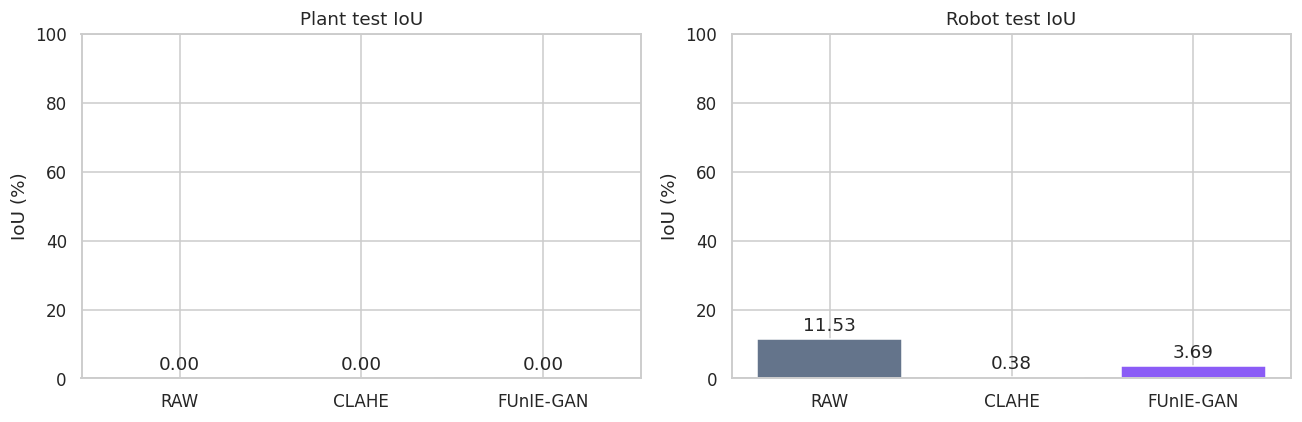

,RAW,CLAHE,FUnIE-GAN
water,6.58%,0.76%,1.78%
diver,0.00%,0.02%,0.05%
plant,0.00%,0.00%,0.00%
wreck,19.50%,9.69%,9.35%
robot,0.01%,0.00%,0.00%
reef,68.87%,79.29%,84.16%
fish,2.29%,3.72%,2.74%
sea-floor,2.75%,6.51%,1.91%


,RAW,CLAHE,FUnIE-GAN
water,18.88%,12.88%,21.82%
diver,56.25%,67.35%,25.61%
plant,0.00%,0.00%,0.00%
wreck,0.27%,4.74%,1.02%
robot,12.78%,0.39%,3.91%
reef,1.64%,2.18%,8.34%
fish,10.10%,10.74%,38.92%
sea-floor,0.08%,1.72%,0.39%


In [ ]:
targets=per_class[per_class['class'].isin(['plant','robot'])].copy()
targets['condition']=targets['method'].map(LABELS)
display(targets[['class','condition','iou','precision','recall','gt_pixels','predicted_pixels']].sort_values(['class','condition']).style.format({'iou':'{:.2%}','precision':'{:.2%}','recall':'{:.2%}'}))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,name in zip(axes,['plant','robot']):
    sub=targets[targets['class']==name].set_index('method').loc[METHODS]
    bars=ax.bar([LABELS[m] for m in METHODS],sub['iou']*100,color=['#64748b','#16a34a','#8b5cf6'])
    ax.bar_label(bars,fmt='%.2f',padding=3)
    ax.set(title=f'{name.title()} test IoU',ylabel='IoU (%)',ylim=(0,100))
fig.tight_layout();fig.savefig(FIG/'03_plant_robot_iou.png',bbox_inches='tight');plt.show()
for name in ['plant','robot']:
    k=CLASSES.index(name)
    distribution=pd.DataFrame({LABELS[m]:cms[:,j].sum(axis=0)[k]/max(cms[:,j].sum(axis=0)[k].sum(),1) for j,m in enumerate(METHODS)},index=CLASSES)
    display(distribution.style.format('{:.2%}').set_caption(f'Predicted labels among true {name} pixels'))
    distribution.to_csv(OUT/f'{name}_prediction_distribution.csv',index_label='predicted_class')

## 8. Statistical Reliability of the Comparisons

`04_controlled_segmentation_evaluation.ipynb` used **2,000 paired image-level bootstrap resamples**, with random seed **42**, to quantify uncertainty in enhanced-minus-RAW differences. The 95% percentile interval for CLAHE's mIoU difference was **[−14.67, −10.16] percentage points**, centered on an observed difference of **−12.42 points**. For FUnIE-GAN, the observed mIoU difference was **−11.22 points**, with interval **[−13.70, −8.60] points**. Both intervals remained below zero.

Pixel accuracy showed the same direction: CLAHE **−19.01 points**, 95% interval **[−22.76, −15.41]**; FUnIE-GAN **−10.71 points**, interval **[−13.47, −8.03]**. Robot IoU differences were also negative, with intervals **[−17.77, −3.47]** for CLAHE and **[−14.95, −1.74]** for FUnIE-GAN. Plant IoU differences were exactly zero because no condition produced plant predictions.

Pairing preserves the relationship between predictions on the same image and is appropriate for this controlled comparison. These intervals describe resampling uncertainty within the evaluated test set; they do not account for alternative model seeds, underwater environments, or independently collected datasets.

,condition,metric,observed_delta,ci_lower,ci_upper,valid_replicates
0,CLAHE,miou,-12.42%,-14.67%,-10.16%,2000
1,CLAHE,pixel_accuracy,-19.01%,-22.76%,-15.41%,2000
2,CLAHE,plant_iou,+0.00%,+0.00%,+0.00%,2000
3,CLAHE,robot_iou,-11.15%,-17.77%,-3.47%,2000
4,FUnIE-GAN,miou,-11.22%,-13.70%,-8.60%,2000
5,FUnIE-GAN,pixel_accuracy,-10.71%,-13.47%,-8.03%,2000
6,FUnIE-GAN,plant_iou,+0.00%,+0.00%,+0.00%,2000
7,FUnIE-GAN,robot_iou,-7.84%,-14.95%,-1.74%,2000


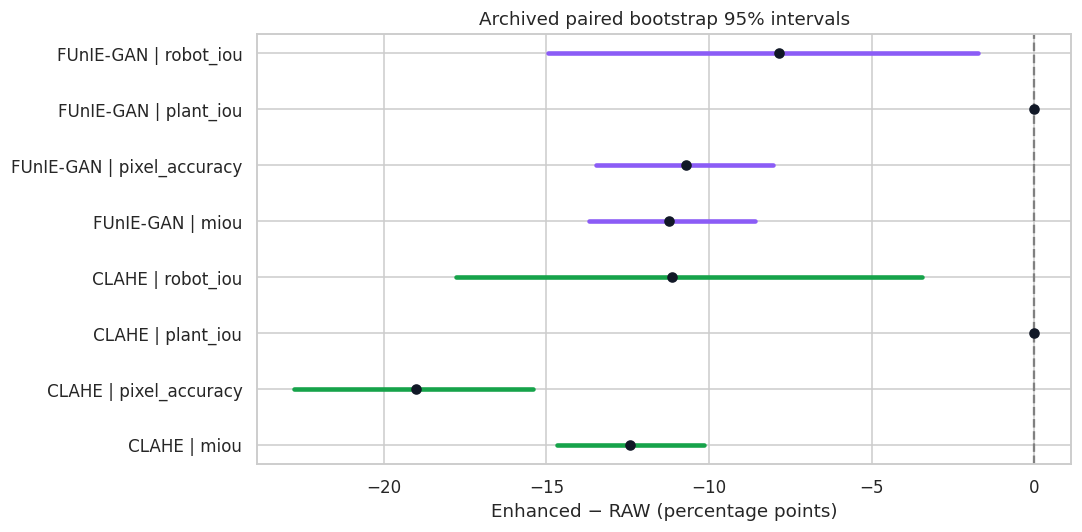

In [ ]:
assert {'method','metric','observed_delta','ci_lower','ci_upper','valid_replicates'}.issubset(bootstrap.columns)
assert set(bootstrap['method'])=={'clahe','funie_gan'}
assert (bootstrap['valid_replicates']>0).all()
show=bootstrap.copy()
show['condition']=show.method.map(LABELS)
display(show[['condition','metric','observed_delta','ci_lower','ci_upper','valid_replicates']].style.format({'observed_delta':'{:+.2%}','ci_lower':'{:+.2%}','ci_upper':'{:+.2%}'}))
fig,ax=plt.subplots(figsize=(10,5))
for i,row in enumerate(show.itertuples(index=False)):
    ax.plot([row.ci_lower*100,row.ci_upper*100],[i,i],color='#8b5cf6' if row.method=='funie_gan' else '#16a34a',lw=3)
    ax.scatter(row.observed_delta*100,i,color='#111827',s=35,zorder=3)
ax.axvline(0,ls='--',color='gray')
ax.set_yticks(range(len(show)),[f'{LABELS[r.method]} | {r.metric}' for r in show.itertuples(index=False)])
ax.set(xlabel='Enhanced − RAW (percentage points)',title='Archived paired bootstrap 95% intervals')
fig.tight_layout();fig.savefig(FIG/'04_bootstrap_intervals.png',bbox_inches='tight');plt.show()
bootstrap.to_csv(OUT/'archived_bootstrap_interval_summary.csv',index=False)

## 9. Computational Efficiency and Practical Implications

Segmentation inference medians were similar across conditions: **5.341 ms** for RAW, **5.307 ms** for CLAHE, and **5.294 ms** for FUnIE-GAN. The RAW mean of **33.171 ms** was distorted by an extreme **3,053.225 ms** observation, so a comparison based on means alone would misrepresent typical inference behavior.

Enhancement adds a separate preprocessing stage. The previously recorded mean enhancement times were **2.177 ms** for CLAHE and **9.021 ms** for FUnIE-GAN. Adding these to the respective mean segmentation times gives **indicative**, not directly measured end-to-end, totals of **7.627 ms** and **14.598 ms**. These values should not be interpreted as synchronized full-pipeline benchmarks.

For an underwater robotic perception pipeline, the practical trade-off is unfavorable in this experiment: both transformations introduce preprocessing work while reducing segmentation quality. Real-time suitability would require repeatable, device-specific end-to-end measurements, including data transfer and image acquisition, which were outside this study.

,method,mean,median,std,min,max
0,clahe,5.450,5.307,0.463,5.125,7.803
1,funie_gan,5.576,5.294,0.947,5.128,13.062
2,raw,33.171,5.341,290.593,5.133,3053.225


,method,mean,median,enhancement_mean_ms,enhancement_median_ms,indicative_sequential_mean_ms
0,clahe,5.450,5.307,2.177,2.069,7.627
1,funie_gan,5.576,5.294,9.021,8.954,14.598
2,raw,33.171,5.341,0.000,NaN,33.171


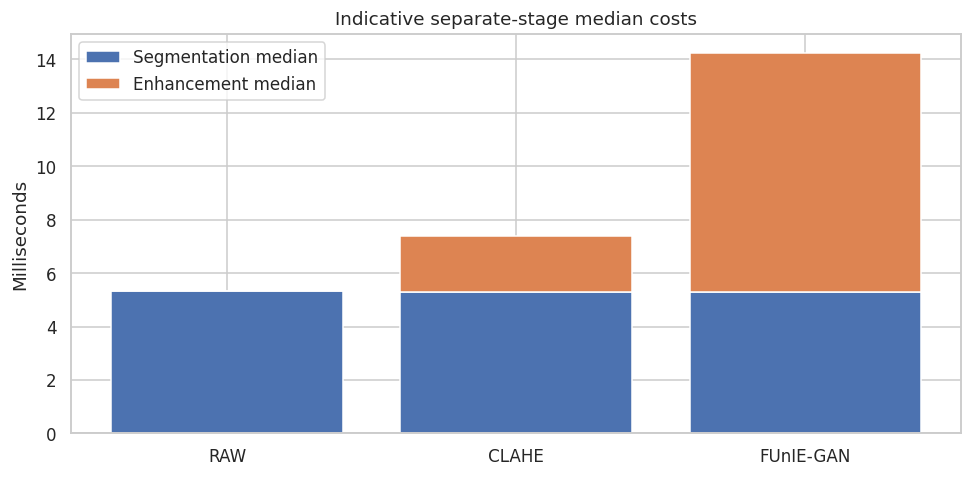

In [ ]:
display(inference.round(3))
display(pipeline.round(3))
assert {'method','median'}.issubset(inference.columns)
assert {'method','enhancement_median_ms'}.issubset(pipeline.columns)
merged=inference[['method','median']].rename(columns={'median':'segmentation_median_ms'}).merge(pipeline[['method','enhancement_median_ms']],on='method')
merged['enhancement_median_ms']=merged['enhancement_median_ms'].fillna(0)
merged=merged.set_index('method').loc[METHODS].reset_index()
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(len(METHODS))
ax.bar(x,merged.segmentation_median_ms,label='Segmentation median')
ax.bar(x,merged.enhancement_median_ms,bottom=merged.segmentation_median_ms,label='Enhancement median')
ax.set_xticks(x,[LABELS[m] for m in METHODS]);ax.set(ylabel='Milliseconds',title='Indicative separate-stage median costs')
ax.legend();fig.tight_layout();fig.savefig(FIG/'05_processing_costs.png',bbox_inches='tight');plt.show()
merged.to_csv(OUT/'median_processing_components.csv',index=False)

## 10. Visual Error Analysis and Representative Cases

The qualitative examples assembled from the archived prediction records provide a visual counterpart to the quantitative comparisons. I examine the same test-image identities across RAW, CLAHE, and FUnIE-GAN so that differences in predicted segmentation masks can be attributed to changed inputs under the fixed model protocol. Ground-truth masks remain unchanged.

These panels are **illustrative cases**, not a substitute for the pooled confusion-matrix results or the paired bootstrap analysis. In particular, visually appealing enhancement should not be interpreted as successful semantic recognition. The quantitative evidence indicates persistent plant omission and substantial robot-class degradation, while individual images may show different local error patterns. I therefore interpret each displayed example in the context of its actual mask and avoid generalizing from a small visual selection.

In [ ]:
assert {'stem','raw','clahe','funie_gan','clahe_delta','funie_gan_delta'}.issubset(per_image.columns)
rows=[]
for m in ['clahe','funie_gan']:
    col=f'{m}_delta'
    ranked=per_image[['stem',col]].sort_values(col)
    for label,subset in [('largest regression',ranked.head(3)),('largest improvement',ranked.tail(3).iloc[::-1])]:
        for r in subset.itertuples(index=False):
            rows.append({'condition':LABELS[m],'case_type':label,'stem':r.stem,'delta_image_miou':getattr(r,col)})
case_table=pd.DataFrame(rows)
display(case_table.style.format({'delta_image_miou':'{:+.2%}'}))
case_table.to_csv(OUT/'selected_image_cases.csv',index=False)
from IPython.display import Image as IPyImage
archived=ROOT/'results/figures/notebook_04'
for filename in ['clahe_largest_changes.png','funie_gan_largest_changes.png']:
    path=archived/filename
    if path.is_file():
        print('Archived qualitative figure:',filename)
        display(IPyImage(filename=str(path),width=1000))
    else:
        print('Archived panel not found:',path,'— case identities remain available above.')

Output hidden; open in https://colab.research.google.com to view.

## 11. Integrated Research Findings

The combined evidence supports three main findings. First, `03_underwater_image_enhancement.ipynb` demonstrated measurable changes in underwater image statistics, but these changes did not correspond to higher test-set segmentation accuracy for the frozen U-Net. Second, `04_controlled_segmentation_evaluation.ipynb` established consistent overall degradation for both enhanced inputs, with negative paired-bootstrap intervals for mIoU and pixel accuracy. Third, the plant and robot analyses revealed that enhancement did not correct the most consequential class-specific weaknesses and, for robot pixels, substantially reduced recall.

The controlled design strengthens the comparison because the same model and annotations were used for all 110 test images. At the same time, it narrows the claim: the experiment evaluates **test-time enhancement of a RAW-trained model**, rather than the best possible performance of each enhancement method under separate training or domain adaptation. The central lesson is that image appearance and downstream task performance must be assessed independently.

In [ ]:
integrated = overall[['method','miou','pixel_accuracy','delta_miou_vs_raw','delta_accuracy_vs_raw']].copy()
integrated['condition']=integrated.method.map(LABELS)
integrated=integrated[['condition','miou','pixel_accuracy','delta_miou_vs_raw','delta_accuracy_vs_raw']]
display(integrated.style.format({k:'{:.2%}' for k in integrated.columns if k!='condition'}))
integrated.to_csv(OUT/'final_research_summary.csv',index=False)
print('Overall test result:', 'RAW ranks highest' if overall.set_index('method').loc['raw','miou'] == overall.miou.max() else 'Review metric ranking')
print('Final synthesis figures:',FIG)
print('Final synthesis tables:',OUT)

,condition,miou,pixel_accuracy,delta_miou_vs_raw,delta_accuracy_vs_raw
0,RAW,44.23%,76.83%,0.00%,0.00%
1,CLAHE,31.80%,57.83%,-12.42%,-19.01%
2,FUnIE-GAN,33.01%,66.12%,-11.22%,-10.71%


Overall test result: RAW ranks highest
Final synthesis figures: /content/drive/MyDrive/Underwater_Research/results/figures/notebook_05
Final synthesis tables: /content/drive/MyDrive/Underwater_Research/results/tables/notebook_05


## 12. Critical Discussion, Limitations, Conclusion, and Future Research

### 12.1 Discussion

The study asked whether CLAHE or FUnIE-GAN would improve underwater semantic segmentation when introduced before an existing RAW-trained U-Net. The evidence indicates that neither transformation improved overall mIoU, pixel accuracy, or any individual class IoU on the official SUIM test set. RAW remained the strongest condition at **44.23% mIoU**, compared with **31.80%** for CLAHE and **33.01%** for FUnIE-GAN. The negative paired-bootstrap intervals suggest that these observed reductions are not driven solely by a small number of test images.

The results are consistent with the possibility that changing image contrast, colors, and texture statistics can interfere with features learned from unmodified training images. However, this explanation remains a hypothesis rather than a demonstrated causal mechanism. The distinction between perceptual enhancement and task utility is the most important scientific finding of this work.

### 12.2 Limitations

The evaluation used one dataset, one RAW-trained U-Net architecture, one selected checkpoint, and fixed enhancement configurations. It did not test models retrained on CLAHE or FUnIE-GAN inputs, alternative enhancement strengths, multiple training seeds, or other underwater domains. The plant class had zero predicted pixels even in the RAW baseline, limiting conclusions about enhancement-specific plant effects. The validation-set image-quality descriptors were not paired image-by-image with the test-set segmentation outcomes. Timing figures were collected in separate stages and do not establish real-world end-to-end robotic latency.

### 12.3 Conclusion

**Under the controlled fixed-model conditions of this study, underwater image enhancement did not improve CNN-based semantic segmentation.** Both CLAHE and FUnIE-GAN reduced overall test performance, and neither recovered plant segmentation or improved robot IoU. The RAW input condition therefore provided the most reliable segmentation results among the three tested alternatives. This finding should not be generalized to all enhancement algorithms or to segmentation models trained on enhanced imagery.

### 12.4 Future Research

A logical next step is to train and evaluate enhancement-specific models under matched training budgets, thereby separating the effects of input transformation from train–test appearance mismatch. Further work could examine class imbalance, targeted plant and robot recognition, robustness across underwater conditions, repeated training seeds, and synchronized end-to-end deployment timing. These are proposed extensions and were **not** performed as part of the present experiments.

### 12.5 Research Reproducibility

The supporting records are documented in `01_data_exploration_cleaning.ipynb`, `02_unet_baseline.ipynb`, `03_underwater_image_enhancement.ipynb`, and `04_controlled_segmentation_evaluation.ipynb`. This final synthesis is preserved in `05_final_research_analysis.ipynb`. The analysis retains the original experimental artifacts and reports observed findings without additional training or test-set tuning.